# 01 — Data analysis: AI-adaptive vs traditional learning (RCT)

**Authors:** Nurali Seifulla, Nurbakyt Sagidulla · **Design:** two-arm parallel-group RCT, 1:1, stratified by pre-test tercile

**Research question (RQ1).** How does learning with an AI-based adaptive platform affect university students' score gain and time on task compared with traditional learning?

* **H₀:** μ_gain(adaptive) − μ_gain(traditional) = 0  ·  **H₁:** the difference ≠ 0
* **Primary metric:** difference in mean score gain (points), 95% bootstrap CI, Hedges' g
* **Guardrails:** platform error rate ≤ 2%, p95 latency ≤ 1000 ms, attrition ≤ 15%

> ⚠️ **Data status.** `data/raw/test_run.jsonl` is a **simulated** log produced by `src/simulate_data.py` (seed 42) in the exact format the platform will export. The numbers below demonstrate the analysis; they are **not** empirical findings. Re-running this notebook on the real log requires no code changes.

The notebook calls the reusable functions in `src/process_data.py` and `src/visualize.py`, so the notebook, the scripts and the README always report the same numbers.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import process_data as pdp
import visualize as viz

cfg = pdp.load_config(ROOT / "configs" / "config.yaml")
SEED = cfg["experiment"]["random_seed"]
np.random.seed(SEED)                 # fixed seed for any global-state sampling
rng = lambda: np.random.default_rng(SEED)  # fresh generator with the same seed for each step
pd.set_option("display.precision", 2)
%matplotlib inline
print("Repository root:", ROOT.name)
print("Seed:", SEED, "| bootstrap resamples:", cfg["analysis"]["n_bootstrap"],
      "| warm-up sessions:", cfg["analysis"]["warmup_sessions"])

Repository root: work
Seed: 42 | bootstrap resamples: 10000 | warm-up sessions: 2


## 1. Data ingestion and warm-up filtering

Each line of the raw log is one event: a `pretest` (week 0), a weekly learning `session` (1–8) or a `posttest` (week 9).
Sessions 1–2 are the **warm-up phase**: students are onboarding and the adaptive model has no history yet (cold start), so latency spikes and quiz scores are not representative. They are kept in the raw file, labelled `phase = "warmup"`, and excluded from all session-level statistics.

In [2]:
raw = pdp.load_raw(ROOT / cfg["analysis"]["raw_jsonl"])
print(f"Raw records: {len(raw)}  (simulated: {bool(raw['simulated'].all())})")
display(raw["event"].value_counts().rename("records").to_frame())
display(raw[raw["event"] == "session"].head(3))

Raw records: 1374  (simulated: True)


,records
event,
session,1101
pretest,140
posttest,133


,event,student_id,group,week,score,simulated,run_id,session,phase,status,quiz_score_pct,time_on_task_min,response_latency_ms
1,session,S001,traditional,NaN,NaN,True,S001-s01,1.0,warmup,ok,64.5,88.0,252.4
2,session,S001,traditional,NaN,NaN,True,S001-s02,2.0,warmup,ok,73.6,53.7,174.7
3,session,S001,traditional,NaN,NaN,True,S001-s03,3.0,evaluation,ok,65.3,81.4,239.8


In [3]:
sessions, eval_sessions = pdp.split_sessions(raw, cfg["analysis"]["warmup_sessions"])
print(f"All sessions: {len(sessions)} | warm-up removed: {len(sessions) - len(eval_sessions)} "
      f"| evaluation sessions kept: {len(eval_sessions)}")

# Why the warm-up is removed: cold-start latency in the adaptive arm
ok = sessions[sessions["status"] == "ok"]
display(ok.groupby(["group", "phase"])["response_latency_ms"]
          .agg(median="median", p95=lambda s: s.quantile(0.95), n="count").round(1))

All sessions: 1101 | warm-up removed: 280 | evaluation sessions kept: 821


median     p95    n
group       phase                          
adaptive    evaluation   318.8   621.2  404
            warmup       688.5  1891.9  132
traditional evaluation   185.9   399.2  409
            warmup       186.4   367.4  142

### Data validity and guardrail metrics

Invalid values are counted and the pipeline stops if any exist (they are never silently dropped). Errors are tracked as a **guardrail metric** with Wilson 95% CIs.

In [4]:
validity = pdp.validity_report(raw)
print("Validity checks (all must be 0):", validity)
assert not any(validity.values())

guard = pdp.guardrails(raw, sessions, eval_sessions, cfg)
display(guard)

Validity checks (all must be 0): {'test_scores_out_of_range': 0, 'quiz_scores_out_of_range': 0, 'non_positive_times': 0, 'non_positive_latencies': 0}


,group,guardrail,value,ci_low,ci_high,n,threshold,passed
0,traditional,error_rate_warmup,0.00e+00,0.00e+00,0.03,142,NaN,<NA>
1,traditional,error_rate_evaluation,7.28e-03,2.48e-03,0.02,412,0.02,True
2,traditional,p95_latency_ms_evaluation,3.99e+02,NaN,NaN,409,1000.00,True
3,traditional,attrition,7.04e-02,3.05e-02,0.15,71,0.15,True
4,adaptive,error_rate_warmup,4.35e-02,2.01e-02,0.09,138,NaN,<NA>
5,adaptive,error_rate_evaluation,1.22e-02,5.23e-03,0.03,409,0.02,True
6,adaptive,p95_latency_ms_evaluation,6.21e+02,NaN,NaN,404,1000.00,True
7,adaptive,attrition,2.90e-02,7.99e-03,0.10,69,0.15,True


## 2. Statistical aggregation

Per-student outcomes use the complete-case population (students with both a pre-test and a post-test).
For every metric we report mean ± SD, median, p25/p75, p95/p99 and **percentile-bootstrap 95% CIs** (10 000 resamples, seed 42) for the mean and the median.

In [5]:
students = pdp.student_outcomes(raw, eval_sessions)
print("Students analysed per arm:", students["group"].value_counts(sort=False).to_dict())

summary = pdp.metrics_summary(students, eval_sessions, cfg, rng())
display(summary.round(2))

Students analysed per arm: {'traditional': 66, 'adaptive': 67}


,metric,unit,level,group,n,mean,sd,mean_ci_low,mean_ci_high,median,median_ci_low,median_ci_high,p25,p75,p95,p99
0,score_gain,points,student,traditional,66,12.24,7.30,10.50,14.03,12.00,9.50,14.50,7.00,16.00,23.75,30.40
1,score_gain,points,student,adaptive,67,15.19,7.10,13.48,16.88,15.00,13.00,17.00,10.00,19.00,28.00,32.34
2,posttest_score,points,student,traditional,66,66.47,11.77,63.73,69.27,65.00,61.00,68.00,58.00,75.00,86.75,91.10
3,posttest_score,points,student,adaptive,67,69.61,12.51,66.63,72.57,69.00,66.00,73.00,61.50,79.00,88.00,96.70
4,pretest_score,points,student,traditional,66,54.23,9.26,52.05,56.45,53.50,51.00,57.50,48.00,60.00,68.50,75.10
5,pretest_score,points,student,adaptive,67,54.42,8.66,52.37,56.45,55.00,52.00,58.00,48.50,61.00,65.70,73.04
6,time_on_task,min/session,student,traditional,66,62.73,4.29,61.70,63.75,62.35,61.37,63.66,60.07,65.40,69.01,73.46
7,time_on_task,min/session,student,adaptive,67,54.39,4.68,53.28,55.54,53.53,52.97,55.27,51.49,56.89,62.52,65.68
8,quiz_score,%,session,traditional,409,70.23,13.18,68.95,71.50,70.00,68.30,72.10,61.20,78.90,93.46,99.99
9,quiz_score,%,session,adaptive,404,73.61,12.39,72.43,74.82,74.00,71.90,75.50,64.85,82.62,94.48,99.49


In [6]:
def fmt(row):
    return pd.Series({
        "Mean ± SD": f"{row['mean']:.1f} ± {row['sd']:.1f}",
        "95% CI (mean)": f"[{row['mean_ci_low']:.1f}, {row['mean_ci_high']:.1f}]",
        "Median (p25–p75)": f"{row['median']:.1f} ({row['p25']:.1f}–{row['p75']:.1f})",
        "p95 / p99": f"{row['p95']:.1f} / {row['p99']:.1f}",
        "n": int(row["n"])})

table = (summary[summary["metric"].isin(["score_gain", "time_on_task", "quiz_score", "response_latency"])]
         .set_index(["metric", "unit", "group"]).apply(fmt, axis=1))
table

Mean ± SD   95% CI (mean)  \
metric           unit        group                                        
score_gain       points      traditional     12.2 ± 7.3    [10.5, 14.0]   
                             adaptive        15.2 ± 7.1    [13.5, 16.9]   
time_on_task     min/session traditional     62.7 ± 4.3    [61.7, 63.7]   
                             adaptive        54.4 ± 4.7    [53.3, 55.5]   
quiz_score       %           traditional    70.2 ± 13.2    [68.9, 71.5]   
                             adaptive       73.6 ± 12.4    [72.4, 74.8]   
response_latency ms          traditional   201.9 ± 97.1  [192.5, 211.5]   
                             adaptive     345.8 ± 158.3  [330.7, 361.5]   

                                             Median (p25–p75)      p95 / p99  \
metric           unit        group                                             
score_gain       points      traditional      12.0 (7.0–16.0)    23.8 / 30.4   
                             adaptive        15.0 (10.0–19.0)    28.0 / 32.3   
time_on_task     min/session traditional     62.4 (60.1–65.4)    69.0 / 73.5   
                             adaptive        53.5 (51.5–56.9)    62.5 / 65.7   
quiz_score       %           traditional     70.0 (61.2–78.9)   93.5 / 100.0   
                             adaptive        74.0 (64.9–82.6)    94.5 / 99.5   
response_latency ms          traditional  185.9 (131.3–246.4)  399.2 / 466.5   
                             adaptive     318.8 (233.1–421.7)  621.2 / 871.4   

                                            n  
metric           unit        group             
score_gain       points      traditional   66  
                             adaptive      67  
time_on_task     min/session traditional   66  
                             adaptive      67  
quiz_score       %           traditional  409  
                             adaptive     404  
response_latency ms          traditional  409  
                             adaptive     404

### Hypothesis test (pre-specified)

Primary: two-sided Welch t-test on score gain plus a bootstrap 95% CI of the difference; reject H₀ only if p < 0.05 **and** the CI excludes 0.
Sensitivity: ANCOVA `posttest ~ arm + pretest` and a Mann–Whitney U test.

In [7]:
tests = pdp.inferential_tests(students, cfg, rng())
p, a = tests["primary"], tests["sensitivity_ancova"]
print(f"Δ gain (adaptive − traditional) = {p['mean_difference_adaptive_minus_traditional']:.2f} points, "
      f"95% bootstrap CI [{p['bootstrap_95ci'][0]:.2f}, {p['bootstrap_95ci'][1]:.2f}]")
print(f"Welch t({p['welch_df']:.1f}) = {p['welch_t']:.2f}, p = {p['welch_p_two_sided']:.4f}; "
      f"Hedges g = {p['hedges_g']:.2f}; Mann–Whitney p = {p['mann_whitney_p_two_sided']:.4f}")
print(f"ANCOVA adjusted effect = {a['adjusted_arm_effect']:.2f} points, 95% CI "
      f"[{a['ci95'][0]:.2f}, {a['ci95'][1]:.2f}], p = {a['p_two_sided']:.4f}")
print("Reject H0:", p["reject_h0"])
s = tests["secondary_time_on_task"]
print(f"Time on task Δ = {s['mean_difference_adaptive_minus_traditional_min']:.1f} min/session, "
      f"Welch p = {s['welch_p_two_sided']:.2e}")

Δ gain (adaptive − traditional) = 2.95 points, 95% bootstrap CI [0.54, 5.41]
Welch t(130.8) = 2.36, p = 0.0196; Hedges g = 0.41; Mann–Whitney p = 0.0176
ANCOVA adjusted effect = 2.93 points, 95% CI [0.47, 5.40], p = 0.0199
Reject H0: True
Time on task Δ = -8.3 min/session, Welch p = 1.36e-19


## 3. Visualization and export

All figures use the seaborn *colorblind* palette **and** distinct markers / line styles (baseline: hollow circles, dashed; adaptive: filled squares, solid) so they remain readable in greyscale. Shaded bands and error bars are 95% bootstrap CIs. Every figure is saved to `reports/figures/` as vector PDF and 300-dpi PNG.

In [8]:
curve = pdp.session_curve(sessions, cfg, rng())
out_dir = ROOT / cfg["analysis"]["figures_dir"]
viz.set_style()
display(curve[["group", "session", "phase", "n", "quiz_mean", "quiz_ci_low", "quiz_ci_high"]].round(1).head(8))

,group,session,phase,n,quiz_mean,quiz_ci_low,quiz_ci_high
0,adaptive,1,warmup,67,56.5,53.2,59.9
1,adaptive,2,warmup,65,58.8,56.2,61.4
2,adaptive,3,evaluation,69,66.8,64.1,69.6
3,adaptive,4,evaluation,69,70.5,67.8,73.2
4,adaptive,5,evaluation,67,73.7,70.7,76.6
5,adaptive,6,evaluation,68,74.7,71.9,77.5
6,adaptive,7,evaluation,65,76.2,73.3,79.1
7,adaptive,8,evaluation,66,80.2,77.6,82.8


['reports/figures/fig1_score_vs_session.pdf', 'reports/figures/fig1_score_vs_session.png']


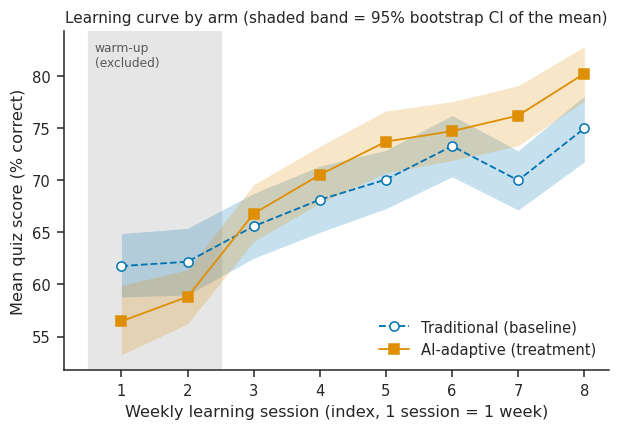

In [9]:
fig1 = viz.fig_score_vs_session(curve, cfg["analysis"]["warmup_sessions"])
print([str(p.relative_to(ROOT)) for p in viz.save(fig1, out_dir, "fig1_score_vs_session")])

['reports/figures/fig2_distribution_boxplot.pdf', 'reports/figures/fig2_distribution_boxplot.png']


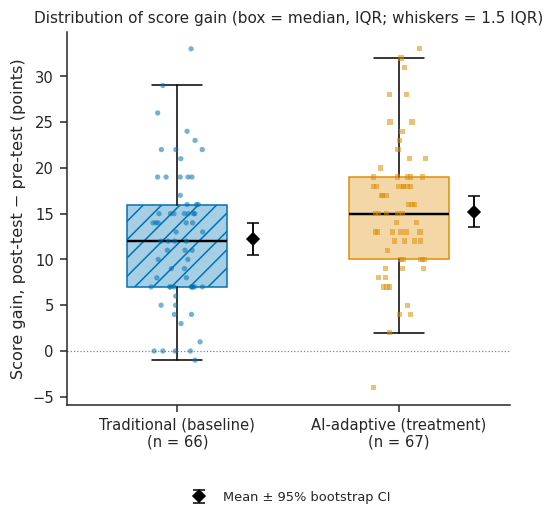

In [10]:
fig2 = viz.fig_gain_boxplot(students, cfg["analysis"]["n_bootstrap"], rng())
print([str(p.relative_to(ROOT)) for p in viz.save(fig2, out_dir, "fig2_distribution_boxplot")])

['reports/figures/fig3_latency_vs_session.pdf', 'reports/figures/fig3_latency_vs_session.png']


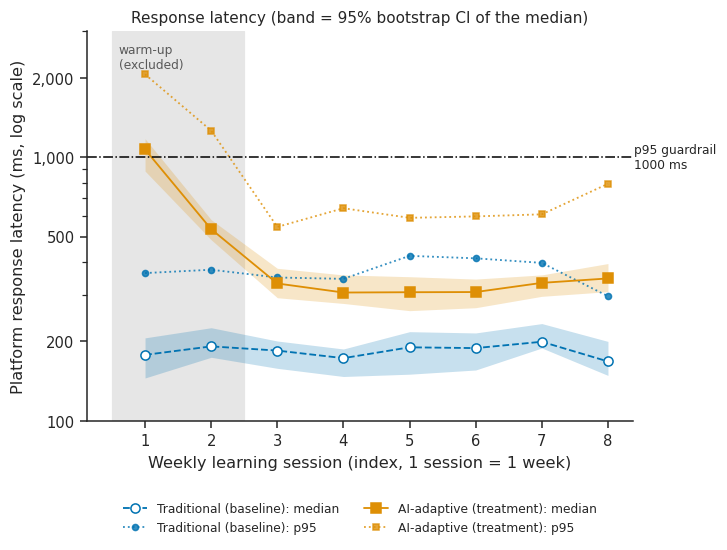

In [11]:
fig3 = viz.fig_latency_vs_session(curve, cfg["analysis"]["warmup_sessions"],
                                  cfg["guardrails"]["max_p95_latency_ms"])
print([str(p.relative_to(ROOT)) for p in viz.save(fig3, out_dir, "fig3_latency_vs_session")])

## 4. Interpretation (simulated data — method demonstration only)

* **Primary metric.** In the simulated log the adaptive arm shows a larger mean score gain; the bootstrap CI excludes zero and the Welch test is below 0.05, so the decision rule would reject H₀. The effect is small-to-moderate (Hedges' g ≈ 0.4) and the ANCOVA gives practically the same estimate, which is expected under successful randomization (pre-test means are balanced).
* **Learning curve (Fig. 1).** The adaptive arm starts *below* the baseline during warm-up — the cold-start period in which the model has no student history — and overtakes it from session 3 onward. Including the warm-up sessions would bias session-level comparisons against the adaptive arm.
* **Guardrails (Fig. 3).** Adaptive latency is higher than the static LMS, and its p95 exceeds 1000 ms only in warm-up session 1; in evaluation sessions p95 stays under the limit. Error rates and attrition are within thresholds in both arms.
* **Caveat.** Because the data are simulated, the effect size is an assumption built into `src/simulate_data.py`, not a result. These statements must be rewritten after the real Week 7–8 log is analysed.

In [12]:
# Persist processed outputs exactly as the CLI pipeline does
proc = ROOT / cfg["analysis"]["processed_dir"]
summary.round(3).to_csv(proc / "metrics_summary.csv", index=False)
print(pd.read_csv(proc / "metrics_summary.csv").shape, "rows/cols written to data/processed/metrics_summary.csv")
import platform, matplotlib, scipy, seaborn
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__, "| seaborn", seaborn.__version__)

(12, 16) rows/cols written to data/processed/metrics_summary.csv
Python 3.11.18 | numpy 2.1.3 | pandas 2.2.3 | scipy 1.14.1 | matplotlib 3.9.2 | seaborn 0.13.2
